# Инициализация

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
import warnings
from scipy import stats

In [2]:
data = pd.read_csv('../data/raw/cars.csv')

# Исследование исходного датасета

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 38531 entries, 0 to 38530
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   manufacturer_name  38531 non-null  str    
 1   model_name         38531 non-null  str    
 2   transmission       38531 non-null  str    
 3   color              38531 non-null  str    
 4   odometer_value     38531 non-null  int64  
 5   year_produced      38531 non-null  int64  
 6   engine_fuel        38531 non-null  str    
 7   engine_has_gas     38531 non-null  bool   
 8   engine_type        38531 non-null  str    
 9   engine_capacity    38521 non-null  float64
 10  body_type          38531 non-null  str    
 11  has_warranty       38531 non-null  bool   
 12  state              38531 non-null  str    
 13  drivetrain         38531 non-null  str    
 14  price_usd          38531 non-null  float64
 15  is_exchangeable    38531 non-null  bool   
 16  location_region    38531 non-null

In [4]:
data.columns

Index(['manufacturer_name', 'model_name', 'transmission', 'color',
       'odometer_value', 'year_produced', 'engine_fuel', 'engine_has_gas',
       'engine_type', 'engine_capacity', 'body_type', 'has_warranty', 'state',
       'drivetrain', 'price_usd', 'is_exchangeable', 'location_region',
       'number_of_photos', 'up_counter', 'feature_0', 'feature_1', 'feature_2',
       'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7',
       'feature_8', 'feature_9', 'duration_listed'],
      dtype='str')

In [5]:
data.head(20)

,manufacturer_name,model_name,transmission,color,odometer_value,year_produced,engine_fuel,engine_has_gas,engine_type,engine_capacity,...,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,duration_listed
0,Subaru,Outback,automatic,silver,190000,2010,gasoline,False,gasoline,2.5,...,True,True,True,False,True,False,True,True,True,16
1,Subaru,Outback,automatic,blue,290000,2002,gasoline,False,gasoline,3.0,...,True,False,False,True,True,False,False,False,True,83
2,Subaru,Forester,automatic,red,402000,2001,gasoline,False,gasoline,2.5,...,True,False,False,False,False,False,False,True,True,151
3,Subaru,Impreza,mechanical,blue,10000,1999,gasoline,False,gasoline,3.0,...,False,False,False,False,False,False,False,False,False,86
4,Subaru,Legacy,automatic,black,280000,2001,gasoline,False,gasoline,2.5,...,True,False,True,True,False,False,False,False,True,7
5,Subaru,Outback,automatic,silver,132449,2011,gasoline,False,gasoline,2.5,...,True,False,False,False,True,False,True,True,True,67
6,Subaru,Forester,automatic,black,318280,1998,gasoline,False,gasoline,2.5,...,True,False,False,True,True,False,False,True,True,307
7,Subaru,Legacy,automatic,silver,350000,2004,gasoline,False,gasoline,2.5,...,True,True,False,False,False,False,False,False,True,73
8,Subaru,Outback,automatic,grey,179000,2010,gasoline,False,gasoline,2.5,...,True,True,True,True,True,True,True,True,True,87
9,Subaru,Forester,automatic,silver,571317,1999,gasoline,False,gasoline,2.5,...,True,True,False,False,True,False,False,False,True,43


- **manufacturer_name**, **model_name**, **color**  - нельзя заменить на one hot,скорее всего от них избавимсмся если нет , корреляции на цену
- **engine_type** - поскольку он очень схож с **engine_fuel** но описывает меньше условий, его просто удалисм
- **state** можем заменить на ранговые (0, 1, 2)
- **transmission**,  - можно заменить на бинарный признак (автомат - 1, механика - 0)
- **drivetrain** - можно замеить на ранговые (передний - 0, задний - 1, полный - 2)
-  **location_region**, **body_type**, **engine_fuel** - применим one-hot

In [6]:
data = data.drop(columns=['engine_type'])

# Удаление дубликатов

Полные дубликаты удаляем **до разделения**: иначе одна и та же строка может оказаться и в train, и в test, и модель будет проверяться на объектах, которые уже видела.

In [7]:
int(data.duplicated().sum())

40

In [8]:
data = data.drop_duplicates(ignore_index=True)
int(data.duplicated().sum()), data.shape[0]

(0, 38491)

# Разделение на train и test

Разделяем данные **до кодирования и заполнения пропусков**. Всё, что вычисляется по данным, считаем **только по train** и применяем к test:
- мода для заполнения пропусков в `engine_capacity`;
- ценовые сегменты марок — они считаются по **средней цене**, то есть по целевой переменной. Если посчитать их по всему датасету, в признак попадёт информация о ценах из test — это прямая утечка таргета;
- набор one-hot столбцов.

EDA тоже проводим только на train.

In [9]:
train, test = train_test_split(data, test_size=0.2, random_state=42)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)
train.shape, test.shape

((30792, 29), (7699, 29))

# Кодирование категориальных признаков

In [10]:
ordinal_encode_f1 = OrdinalEncoder(categories=[['emergency', 'owned', 'new']])
ordinal_encode_f2 = OrdinalEncoder(categories=[['front', 'rear', 'all']])
ordinal_encode_f3 = OrdinalEncoder(categories=[['mechanical','automatic']])

# fit — только на train, test лишь преобразуем
train["transmission"] = ordinal_encode_f3.fit_transform(train[["transmission"]])
train["state"] = ordinal_encode_f1.fit_transform(train[["state"]])
train["drivetrain"] = ordinal_encode_f2.fit_transform(train[["drivetrain"]])

test["transmission"] = ordinal_encode_f3.transform(test[["transmission"]])
test["state"] = ordinal_encode_f1.transform(test[["state"]])
test["drivetrain"] = ordinal_encode_f2.transform(test[["drivetrain"]])

In [11]:
def one_hot(df):
    dummies = pd.get_dummies(df[['location_region', 'body_type', 'engine_fuel']],
                             prefix=['loc', 'body', 'fuel'],  # Для удобства
                             drop_first=False)
    # Удаляем исходные категориальные столбцы
    df = df.drop(columns=['location_region', 'body_type', 'engine_fuel'])
    # Объединяем дамми-переменные с оставшимися данными
    return pd.concat([df, dummies], axis=1)

train = one_hot(train)
test = one_hot(test)

# столбцы test приводим к столбцам train: категории, которых нет в test, становятся столбцами из нулей,
# а категории, которых не было в train, модель всё равно не знает — их отбрасываем
test = test.reindex(columns=train.columns, fill_value=0)
train.shape, test.shape

((30792, 50), (7699, 50))

In [12]:
train.head(20)

,manufacturer_name,model_name,transmission,color,odometer_value,year_produced,engine_has_gas,engine_capacity,has_warranty,state,...,body_sedan,body_suv,body_universal,body_van,fuel_diesel,fuel_electric,fuel_gas,fuel_gasoline,fuel_hybrid-diesel,fuel_hybrid-petrol
0,Ford,Focus,1.0,grey,2090,2019,False,1.6,False,1.0,...,False,False,False,False,False,False,False,True,False,False
1,Audi,A6,0.0,silver,303000,2001,False,1.9,False,1.0,...,True,False,False,False,True,False,False,False,False,False
2,Audi,A6,0.0,green,300000,1999,True,2.4,False,1.0,...,True,False,False,False,False,False,True,False,False,False
3,Chevrolet,Cruze,0.0,black,110500,2013,False,1.4,False,1.0,...,True,False,False,False,False,False,False,True,False,False
4,Mercedes-Benz,C180,0.0,silver,196000,2015,False,1.6,False,1.0,...,False,False,True,False,True,False,False,False,False,False
5,Hyundai,Accent,0.0,green,320000,1995,False,1.3,False,1.0,...,False,False,False,False,False,False,False,True,False,False
6,Ford,Fusion,0.0,silver,224520,2005,False,1.4,False,1.0,...,False,False,False,False,True,False,False,False,False,False
7,Peugeot,605,0.0,brown,355000,1999,False,2.1,False,1.0,...,True,False,False,False,True,False,False,False,False,False
8,Mitsubishi,Space Star,0.0,green,300000,1998,False,1.3,False,1.0,...,False,False,True,False,False,False,False,True,False,False
9,Buick,Encore,1.0,black,146000,2013,False,1.4,False,1.0,...,False,True,False,False,False,False,False,True,False,False


# Заполнение пропусков

In [13]:
(train.isna().sum()/train.shape[0]*100).sort_values(ascending=False).head(), int(test.isna().sum().sum())

(engine_capacity         0.029228
 manufacturer_name       0.000000
 body_minivan            0.000000
 loc_Гомельская обл.     0.000000
 loc_Гродненская обл.    0.000000
 dtype: float64,
 1)

In [14]:
# моду считаем по train и ей же заполняем пропуски в обеих частях
mode_value = train['engine_capacity'].mode()[0]
train = train.fillna({'engine_capacity': mode_value})
test = test.fillna({'engine_capacity': mode_value})
mode_value, int(train.isna().sum().sum()), int(test.isna().sum().sum())

(np.float64(2.0), 0, 0)

In [15]:
train['manufacturer_name'].unique()

<StringArray>
[         'Ford',          'Audi',     'Chevrolet', 'Mercedes-Benz',
       'Hyundai',       'Peugeot',    'Mitsubishi',         'Buick',
         'Mazda',       'Pontiac',           'Kia',        'Suzuki',
      'Chrysler',       'Citroen',        'Nissan',    'Volkswagen',
        'Toyota',       'Renault',         'Volvo',          'Fiat',
         'Geely',          'Opel',         'Dodge',         'Skoda',
    'Alfa Romeo',           'ГАЗ',           'ВАЗ',          'Seat',
           'BMW',          'LADA',         'Honda',        'Subaru',
    'Great Wall',       'Porsche',         'Chery',         'Rover',
      'Cadillac',        'Jaguar',    'Land Rover',         'Lexus',
          'Saab',           'ЗАЗ',         'Dacia',       'Lincoln',
       'Москвич',        'Lancia',         'Iveco',          'Mini',
      'Infiniti',         'Acura',           'УАЗ',     'SsangYong',
        'Daewoo',          'Jeep',         'Lifan']
Length: 55, dtype: str

# Коррекция типов данных

In [16]:
df = train[['manufacturer_name', 'year_produced', 'price_usd']]
df

,manufacturer_name,year_produced,price_usd
0,Ford,2019,18021.43
1,Audi,2001,6165.23
2,Audi,1999,5600.00
3,Chevrolet,2013,9000.00
4,Mercedes-Benz,2015,17200.00
...,...,...,...
30787,Citroen,2008,7400.00
30788,Ford,1995,2500.00
30789,Chrysler,1996,620.00
30790,Kia,2014,14900.00


In [17]:
df = df[df['year_produced'] > 2010].reset_index(drop=True)
df

,manufacturer_name,year_produced,price_usd
0,Ford,2019,18021.43
1,Chevrolet,2013,9000.00
2,Mercedes-Benz,2015,17200.00
3,Buick,2013,12950.00
4,Buick,2013,12250.00
...,...,...,...
5786,Kia,2014,15900.00
5787,Suzuki,2011,5700.00
5788,Mitsubishi,2011,7445.70
5789,Volkswagen,2011,17000.00


In [18]:
model = df['manufacturer_name'].unique()
model

<StringArray>
[         'Ford',     'Chevrolet', 'Mercedes-Benz',         'Buick',
         'Geely',           'ГАЗ',       'Hyundai',         'Skoda',
        'Toyota',          'LADA',        'Nissan',           'BMW',
           'Kia',       'Renault',    'Volkswagen',         'Honda',
       'Porsche',        'Suzuki',        'Jaguar',         'Volvo',
         'Lexus',          'Audi',       'Peugeot',       'Citroen',
         'Mazda',          'Opel',     'SsangYong',      'Cadillac',
         'Acura',         'Dacia',          'Fiat',         'Dodge',
        'Subaru',    'Land Rover',      'Infiniti',    'Mitsubishi',
    'Great Wall',         'Lifan',         'Chery',           'ВАЗ',
         'Iveco',          'Mini',        'Daewoo',       'Lincoln',
           'УАЗ',          'Seat',          'Jeep',           'ЗАЗ',
      'Chrysler',          'Saab',    'Alfa Romeo']
Length: 51, dtype: str

Потеряли данные марки, в исходном датасете просто добавим их в бюджетный сегмент. Так же поступим с марками, которых нет в train (они могут встретиться только в test)

In [19]:
models = df['manufacturer_name'].unique()
diff = set(train['manufacturer_name'].unique()) - set(models)
for model in diff:
    print(f'{model}: {train[train["manufacturer_name"] == model].shape[0]}')

Rover: 186
Москвич: 44
Pontiac: 34
Lancia: 72


In [20]:
dictonary = dict()
for model in models:
    mod = df[df["manufacturer_name"] == model]
    mean = mod["price_usd"].sum()/mod.shape[0]
    dictonary[model] = float(round(mean, 2))
    
dictonary

{'Ford': 12867.03,
 'Chevrolet': 10831.99,
 'Mercedes-Benz': 25379.43,
 'Buick': 13005.66,
 'Geely': 9485.03,
 'ГАЗ': 14001.49,
 'Hyundai': 13118.1,
 'Skoda': 18497.51,
 'Toyota': 18572.51,
 'LADA': 8542.28,
 'Nissan': 13585.03,
 'BMW': 23766.76,
 'Kia': 12826.3,
 'Renault': 10220.4,
 'Volkswagen': 13563.61,
 'Honda': 15868.81,
 'Porsche': 31703.86,
 'Suzuki': 11512.29,
 'Jaguar': 29444.28,
 'Volvo': 16682.9,
 'Lexus': 26781.15,
 'Audi': 18750.08,
 'Peugeot': 9897.39,
 'Citroen': 9846.06,
 'Mazda': 15755.8,
 'Opel': 10880.81,
 'SsangYong': 10925.19,
 'Cadillac': 19005.84,
 'Acura': 21375.54,
 'Dacia': 8386.49,
 'Fiat': 11692.36,
 'Dodge': 19557.84,
 'Subaru': 16770.8,
 'Land Rover': 27648.52,
 'Infiniti': 22563.23,
 'Mitsubishi': 15608.45,
 'Great Wall': 9886.18,
 'Lifan': 8689.16,
 'Chery': 7062.55,
 'ВАЗ': 7106.41,
 'Iveco': 23544.87,
 'Mini': 17973.22,
 'Daewoo': 2968.09,
 'Lincoln': 22458.33,
 'УАЗ': 9011.55,
 'Seat': 10373.14,
 'Jeep': 22711.19,
 'ЗАЗ': 3507.89,
 'Chrysler': 24058

In [21]:
prices = list(dictonary.values())
q25 = np.percentile(prices, 25)
q75 = np.percentile(prices, 75)

In [22]:
categorized = {}
for brand, price in dictonary.items():
    if price <= q25:
        categorized[brand] = 0 #Бюджет
    elif price >= q75:
        categorized[brand] = 2 #Премиум
    else:
        categorized[brand] = 1 #Средний

print(f"Пороги: бюджет до {round(q25, 2)}$, премиум от {round(q75, 2)}$")
for i in diff:
    categorized[i] = 0
print(categorized)

Пороги: бюджет до 10058.9$, премиум от 19281.84$
{'Ford': 1, 'Chevrolet': 1, 'Mercedes-Benz': 2, 'Buick': 1, 'Geely': 0, 'ГАЗ': 1, 'Hyundai': 1, 'Skoda': 1, 'Toyota': 1, 'LADA': 0, 'Nissan': 1, 'BMW': 2, 'Kia': 1, 'Renault': 1, 'Volkswagen': 1, 'Honda': 1, 'Porsche': 2, 'Suzuki': 1, 'Jaguar': 2, 'Volvo': 1, 'Lexus': 2, 'Audi': 1, 'Peugeot': 0, 'Citroen': 0, 'Mazda': 1, 'Opel': 1, 'SsangYong': 1, 'Cadillac': 1, 'Acura': 2, 'Dacia': 0, 'Fiat': 1, 'Dodge': 2, 'Subaru': 1, 'Land Rover': 2, 'Infiniti': 2, 'Mitsubishi': 1, 'Great Wall': 0, 'Lifan': 0, 'Chery': 0, 'ВАЗ': 0, 'Iveco': 2, 'Mini': 1, 'Daewoo': 0, 'Lincoln': 2, 'УАЗ': 0, 'Seat': 1, 'Jeep': 2, 'ЗАЗ': 0, 'Chrysler': 2, 'Saab': 1, 'Alfa Romeo': 0, 'Rover': 0, 'Москвич': 0, 'Pontiac': 0, 'Lancia': 0}


In [23]:
train['manufacturer_name'] = train['manufacturer_name'].map(categorized)
# марки, которых не было в train, относим к бюджетному сегменту
test['manufacturer_name'] = test['manufacturer_name'].map(categorized).fillna(0).astype(int)

train = train.drop(columns='model_name')
test = test.drop(columns='model_name')
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 30792 entries, 0 to 30791
Data columns (total 49 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   manufacturer_name     30792 non-null  int64  
 1   transmission          30792 non-null  float64
 2   color                 30792 non-null  str    
 3   odometer_value        30792 non-null  int64  
 4   year_produced         30792 non-null  int64  
 5   engine_has_gas        30792 non-null  bool   
 6   engine_capacity       30792 non-null  float64
 7   has_warranty          30792 non-null  bool   
 8   state                 30792 non-null  float64
 9   drivetrain            30792 non-null  float64
 10  price_usd             30792 non-null  float64
 11  is_exchangeable       30792 non-null  bool   
 12  number_of_photos      30792 non-null  int64  
 13  up_counter            30792 non-null  int64  
 14  feature_0             30792 non-null  bool   
 15  feature_1             30792 no

In [24]:
train = train.drop(columns='color')
test = test.drop(columns='color')
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 30792 entries, 0 to 30791
Data columns (total 48 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   manufacturer_name     30792 non-null  int64  
 1   transmission          30792 non-null  float64
 2   odometer_value        30792 non-null  int64  
 3   year_produced         30792 non-null  int64  
 4   engine_has_gas        30792 non-null  bool   
 5   engine_capacity       30792 non-null  float64
 6   has_warranty          30792 non-null  bool   
 7   state                 30792 non-null  float64
 8   drivetrain            30792 non-null  float64
 9   price_usd             30792 non-null  float64
 10  is_exchangeable       30792 non-null  bool   
 11  number_of_photos      30792 non-null  int64  
 12  up_counter            30792 non-null  int64  
 13  feature_0             30792 non-null  bool   
 14  feature_1             30792 non-null  bool   
 15  feature_2             30792 no

In [25]:
for df_part in (train, test):
    bool_columns = df_part.select_dtypes(include='bool').columns
    df_part[bool_columns] = df_part[bool_columns].astype(int)

In [26]:
col = ['transmission', 'state', 'drivetrain']
for c in col:
    train[c] = train[c].astype(int)
    test[c] = test[c].astype(int)

In [27]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 30792 entries, 0 to 30791
Data columns (total 48 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   manufacturer_name     30792 non-null  int64  
 1   transmission          30792 non-null  int64  
 2   odometer_value        30792 non-null  int64  
 3   year_produced         30792 non-null  int64  
 4   engine_has_gas        30792 non-null  int64  
 5   engine_capacity       30792 non-null  float64
 6   has_warranty          30792 non-null  int64  
 7   state                 30792 non-null  int64  
 8   drivetrain            30792 non-null  int64  
 9   price_usd             30792 non-null  float64
 10  is_exchangeable       30792 non-null  int64  
 11  number_of_photos      30792 non-null  int64  
 12  up_counter            30792 non-null  int64  
 13  feature_0             30792 non-null  int64  
 14  feature_1             30792 non-null  int64  
 15  feature_2             30792 no

# EDA

EDA проводим **только на train**.

In [28]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
manufacturer_name,30792.0,1.031794,0.552580,0.0,1.0,1.0,1.0,2.0
transmission,30792.0,0.335217,0.472074,0.0,0.0,0.0,1.0,1.0
odometer_value,30792.0,249056.531989,136206.846533,0.0,159000.0,250000.0,324000.0,1000000.0
year_produced,30792.0,2002.948461,8.059764,1942.0,1998.0,2003.0,2009.0,2019.0
engine_has_gas,30792.0,0.035074,0.183970,0.0,0.0,0.0,0.0,1.0
engine_capacity,30792.0,2.055773,0.671047,0.2,1.6,2.0,2.3,8.0
has_warranty,30792.0,0.010685,0.102814,0.0,0.0,0.0,0.0,1.0
state,30792.0,1.001332,0.141321,0.0,1.0,1.0,1.0,2.0
drivetrain,30792.0,0.418713,0.723296,0.0,0.0,0.0,1.0,2.0
price_usd,30792.0,6652.887105,6439.988994,1.0,2100.0,4800.0,8999.0,50000.0


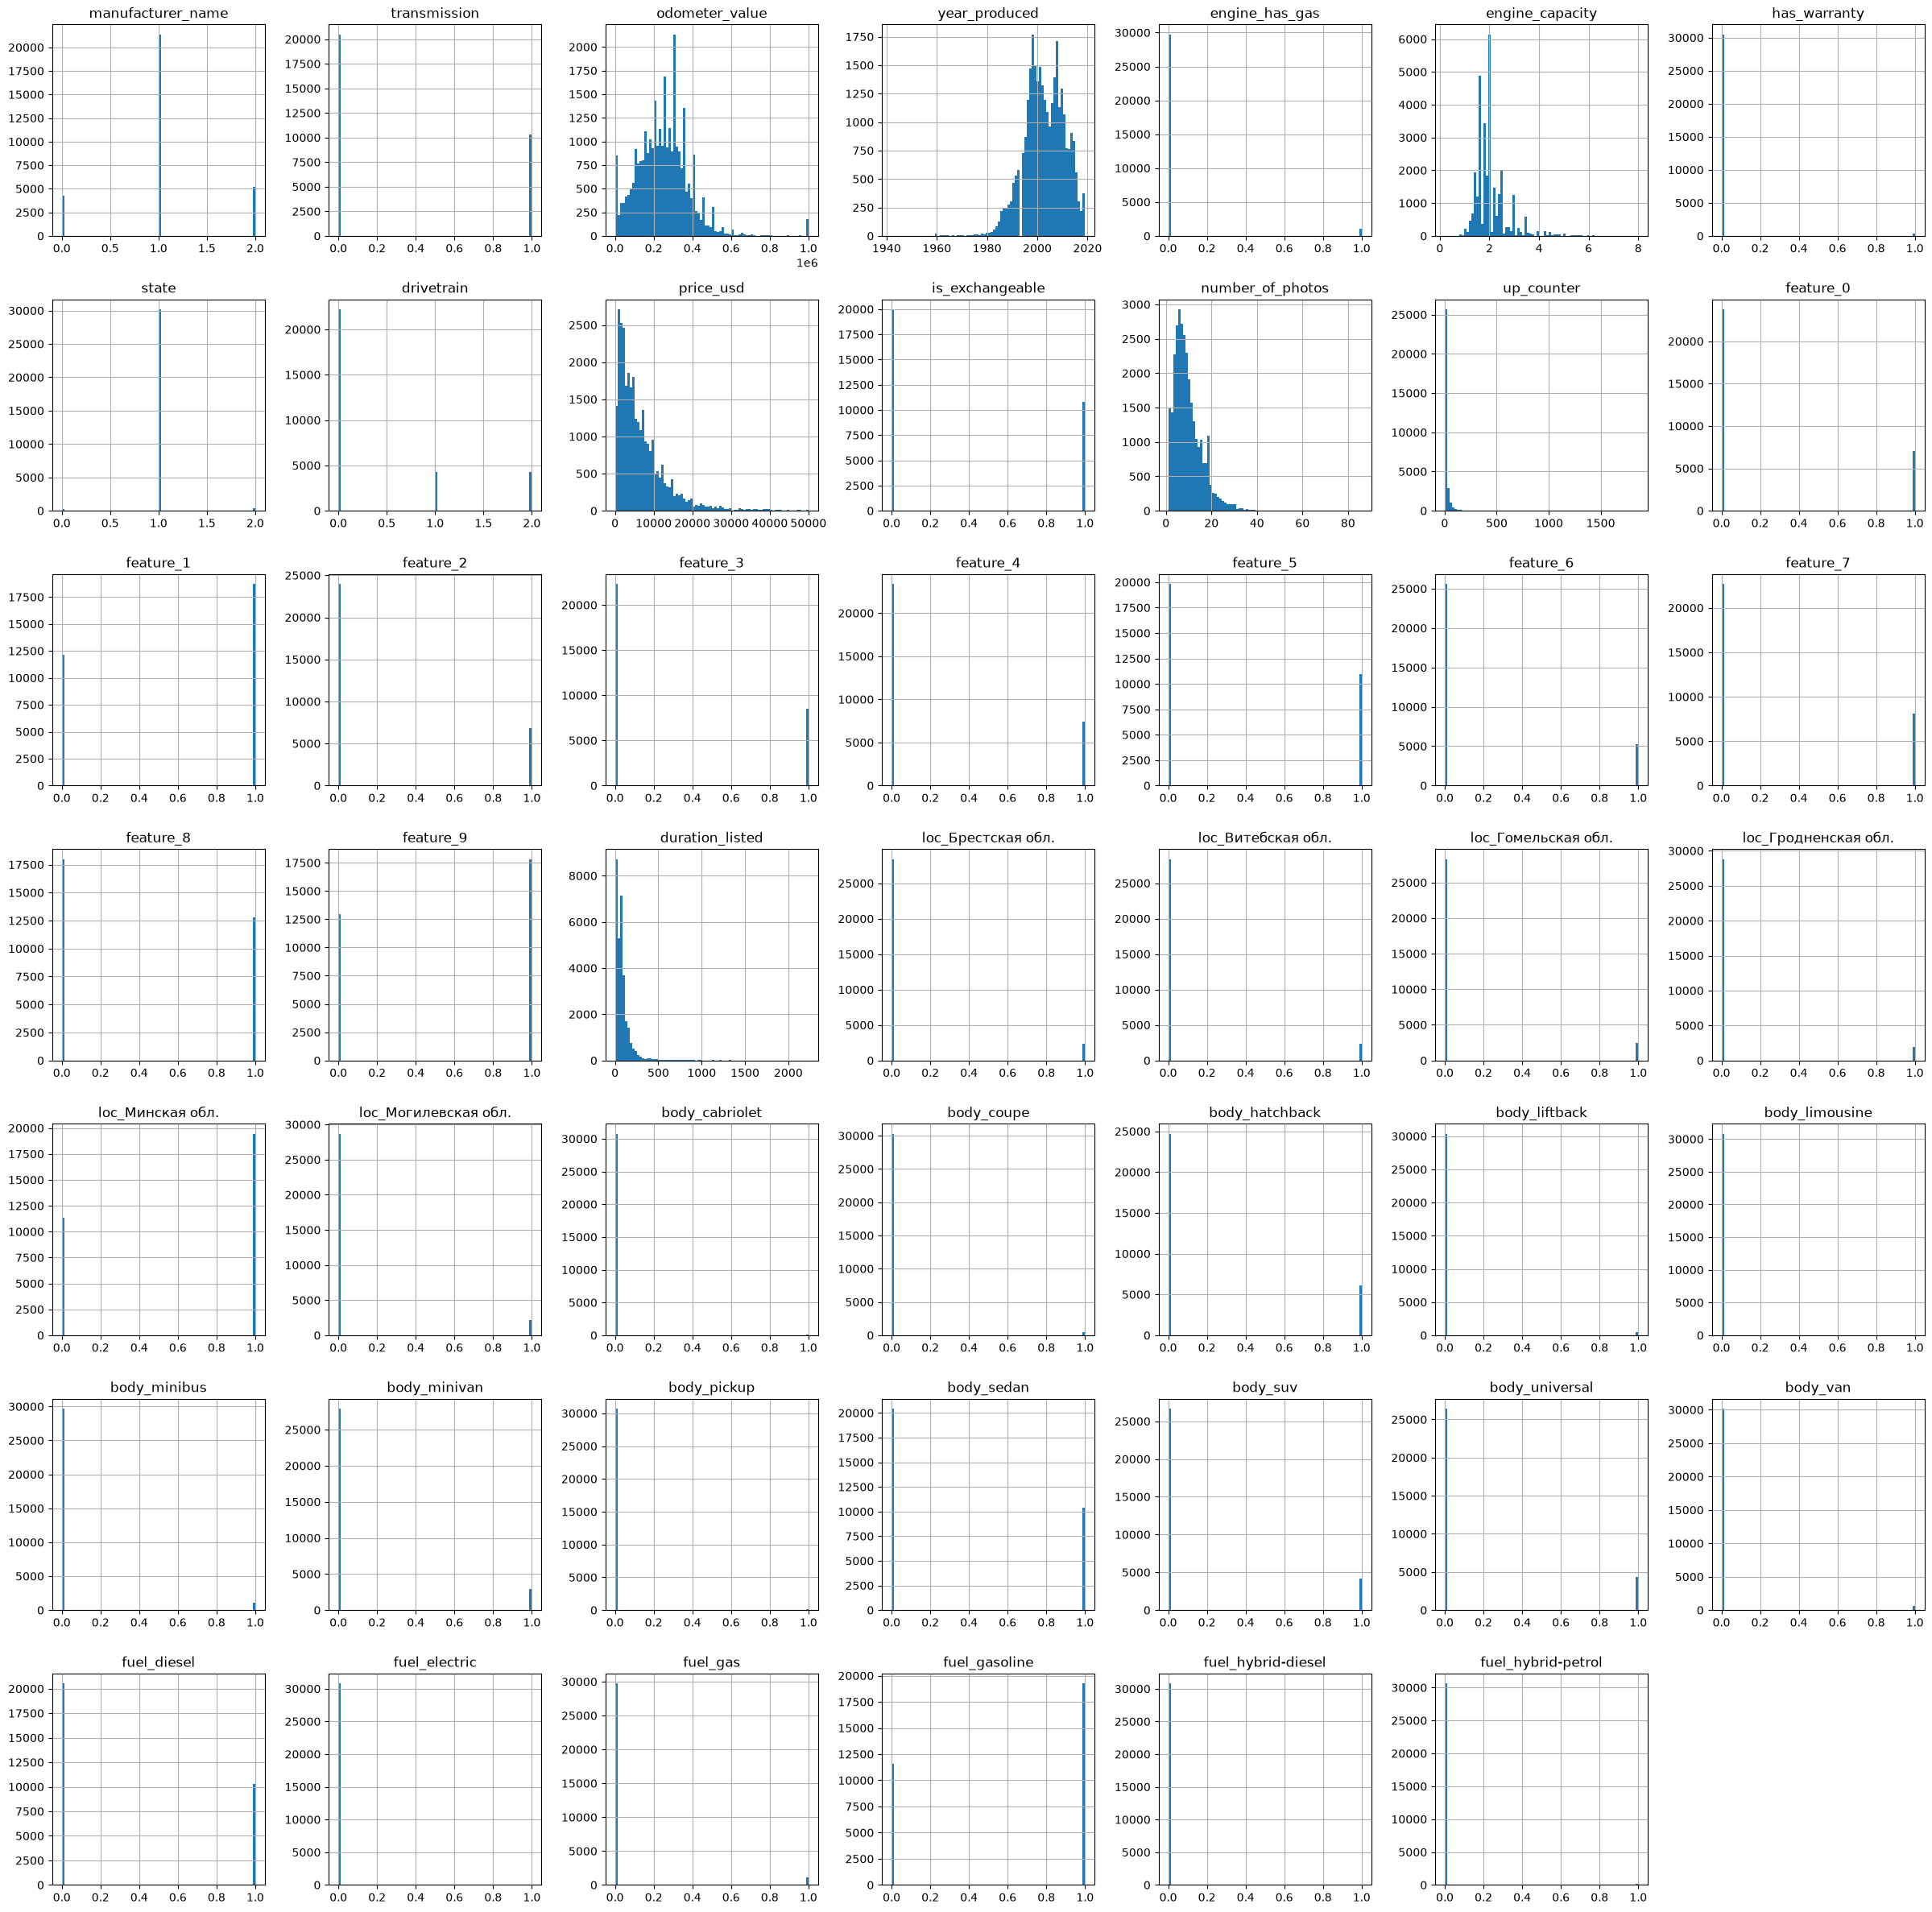

In [29]:
train.hist(figsize=(30, 30), bins=80)
plt.show()

array([[<Axes: title={'center': 'price_usd'}>]], dtype=object)

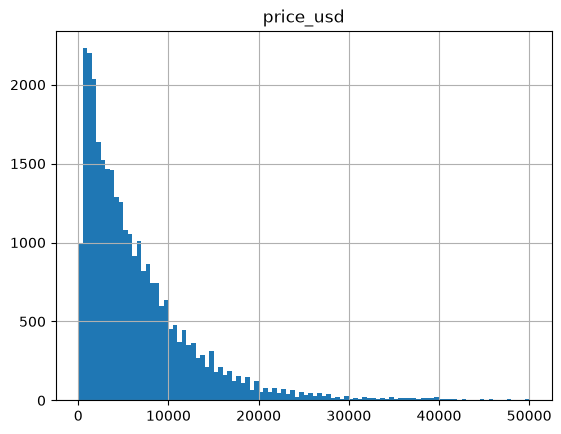

In [30]:
train.hist(column='price_usd', bins=100)

Много дешевых машин и мало дорогих

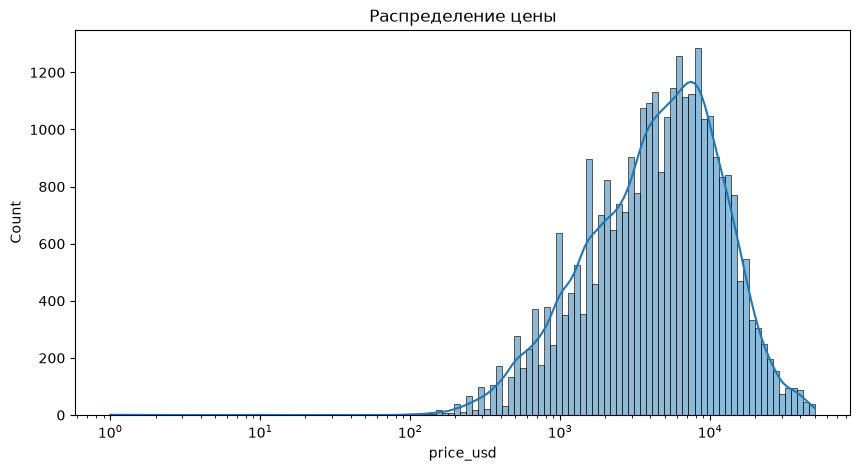

In [31]:
plt.figure(figsize=(10, 5))
# Логарифмируем масштаб оси х
sns.histplot(train['price_usd'], kde=True, log_scale=True)
plt.title('Распределение цены')
plt.show()

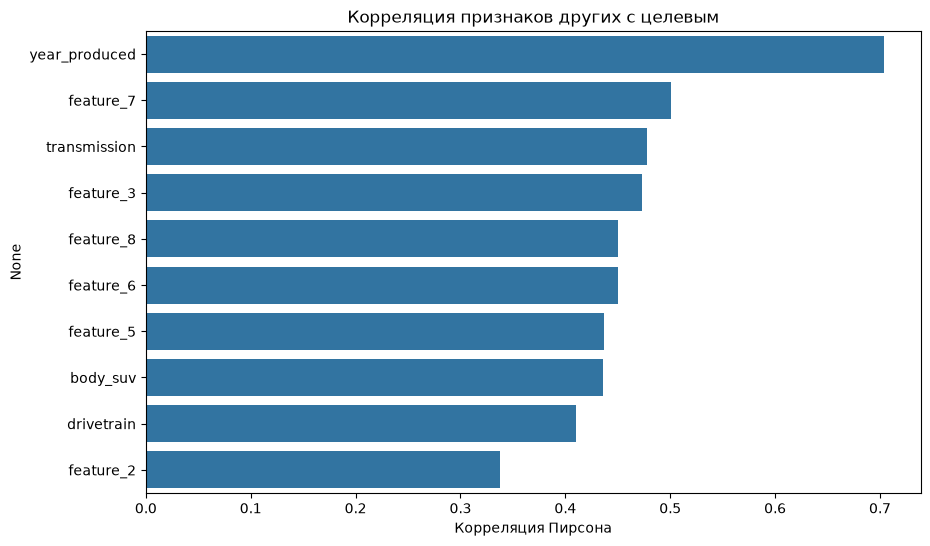

In [32]:
corr_with_price = train.corr(numeric_only=True)['price_usd'].sort_values(ascending=False)

top_features = corr_with_price.drop('price_usd').head(10).index
plt.figure(figsize=(10,6))
sns.barplot(x=corr_with_price[top_features].values, y=top_features)
plt.title('Корреляция признаков других с целевым')
plt.xlabel('Корреляция Пирсона')
plt.show()

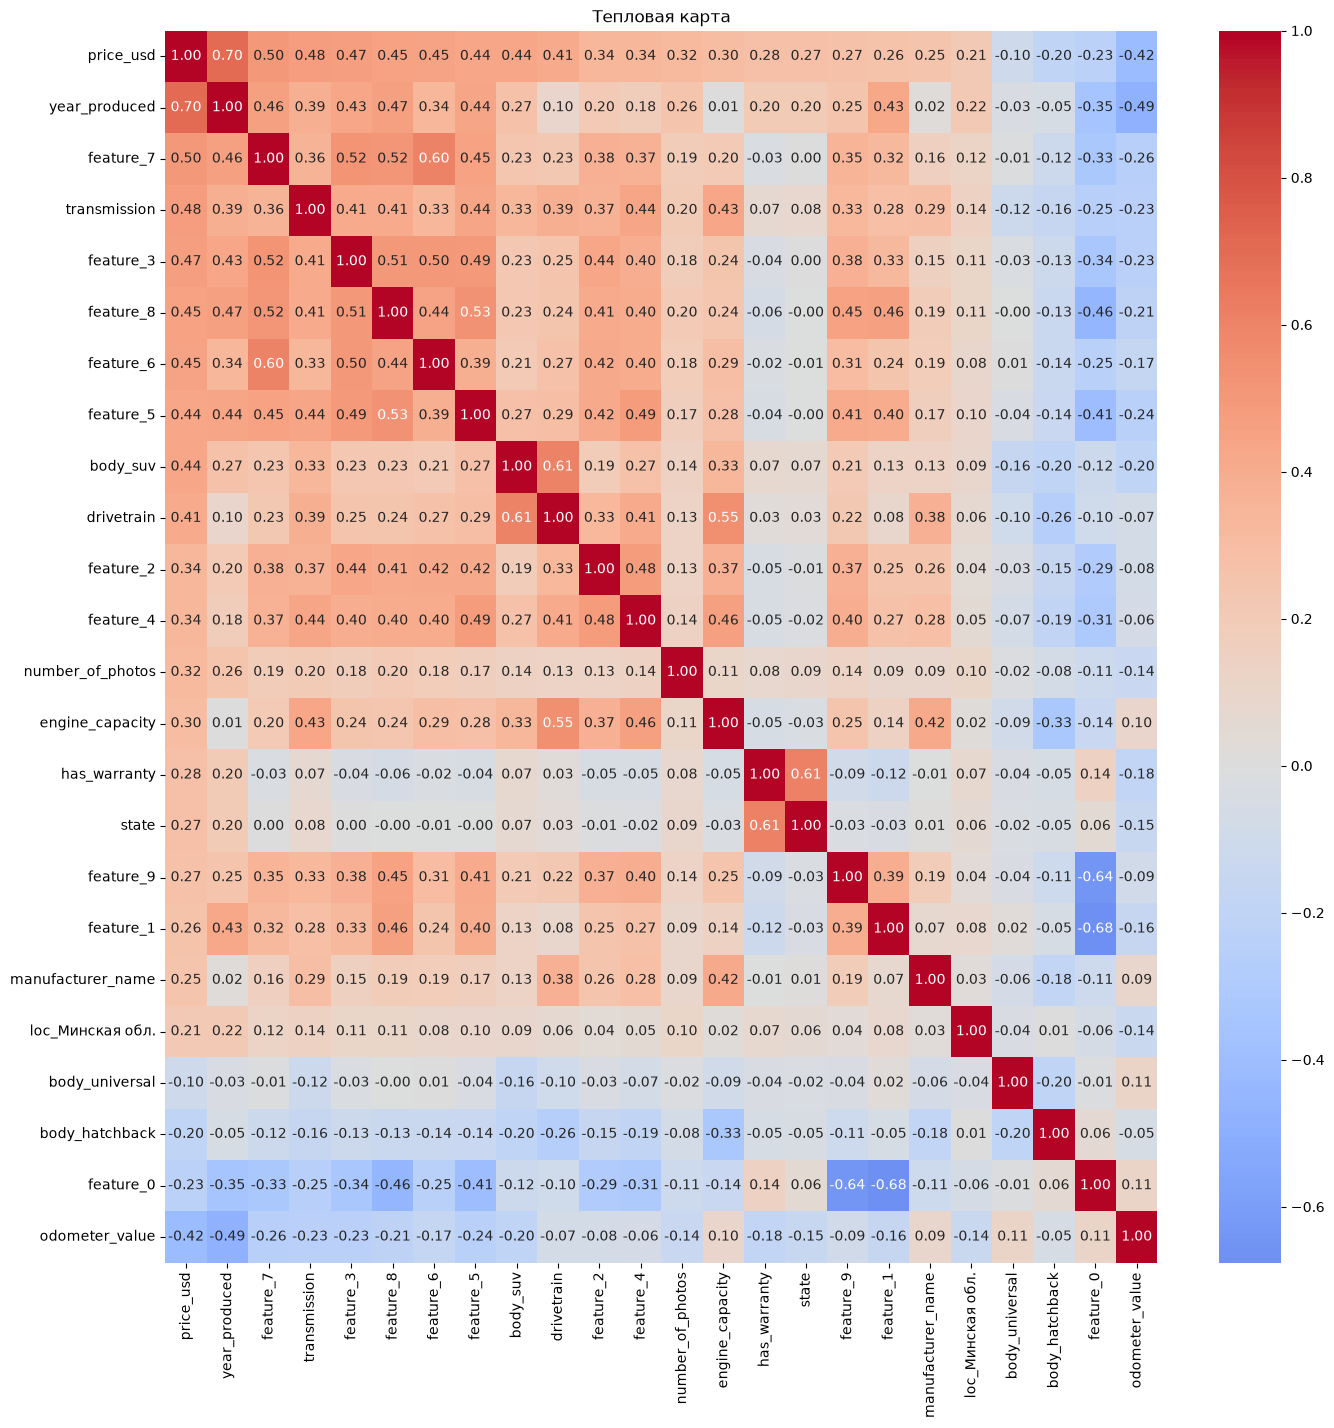

In [33]:
corr_with_price = train.corr(numeric_only=True)['price_usd'].sort_values(ascending=False)
high_corr_features = corr_with_price[abs(corr_with_price) > 0.1].index
plt.figure(figsize=(16,16))
sns.heatmap(train[high_corr_features].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Тепловая карта')
plt.show()

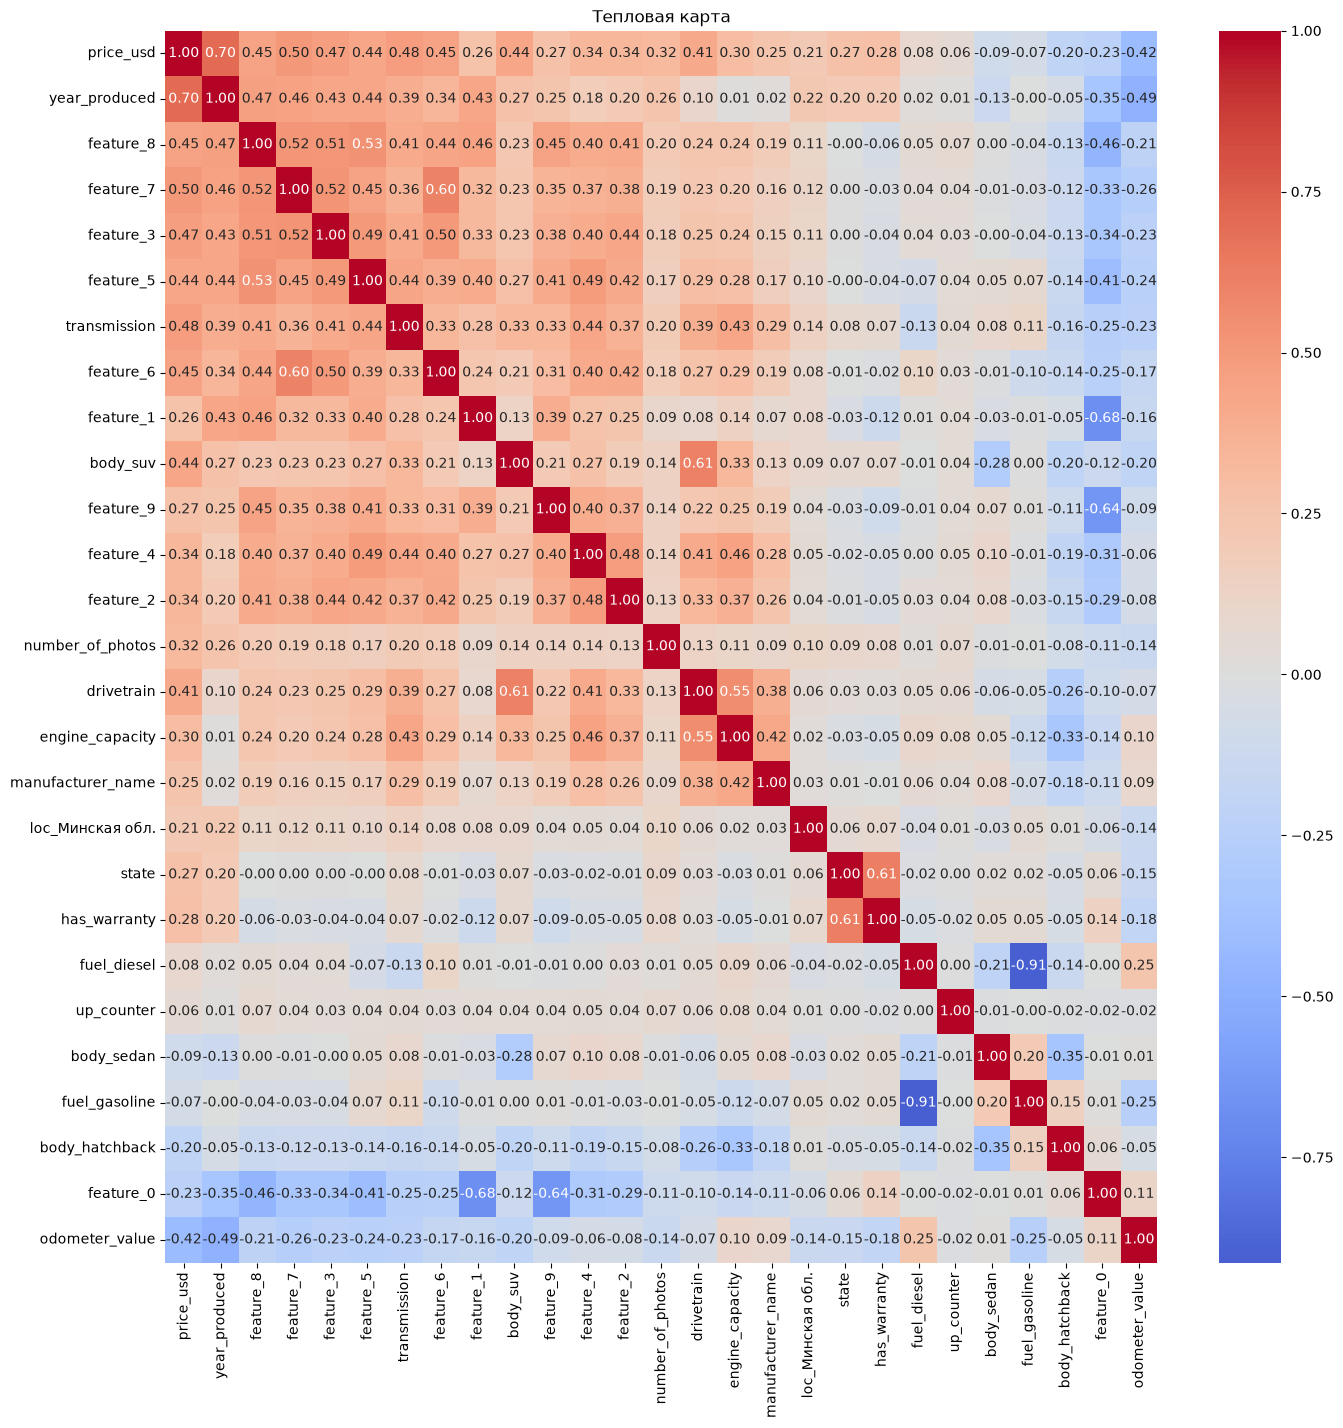

In [34]:
corr_with_price = train.corr(numeric_only=True, method='spearman')['price_usd'].sort_values(ascending=False)
high_corr_features = corr_with_price[abs(corr_with_price) > 0.1].index
plt.figure(figsize=(16,16))
sns.heatmap(train[high_corr_features].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Тепловая карта')
plt.show()

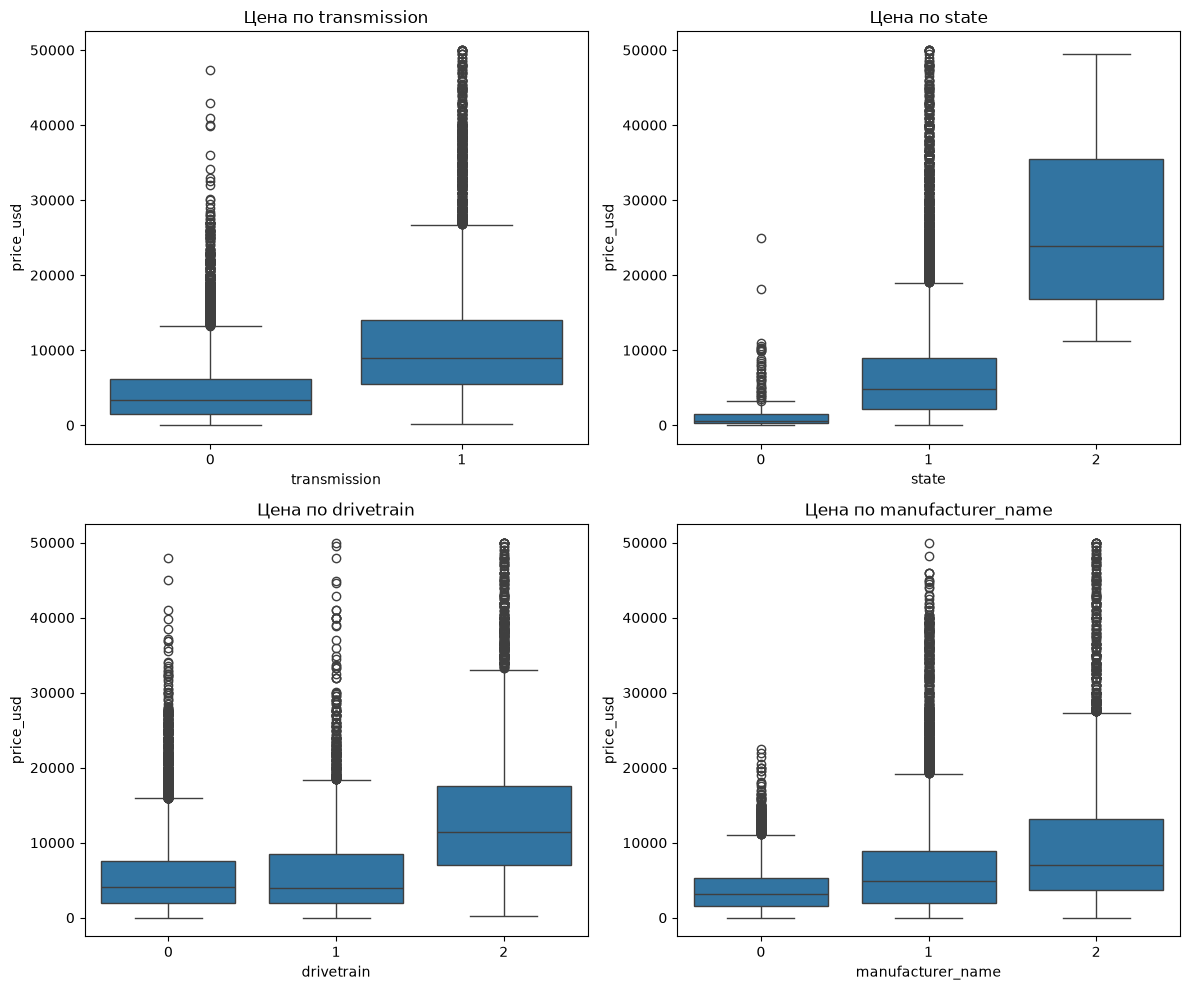

In [35]:
ordinal_cols = ['transmission', 'state', 'drivetrain', 'manufacturer_name']
fig, axes = plt.subplots(2,2, figsize=(12,10))
for ax, col in zip(axes.ravel(), ordinal_cols):
    sns.boxplot(data=train, x=col, y='price_usd', ax=ax)
    ax.set_title(f'Цена по {col}')
plt.tight_layout()
plt.show()

In [36]:
train.head(20)

,manufacturer_name,transmission,odometer_value,year_produced,engine_has_gas,engine_capacity,has_warranty,state,drivetrain,price_usd,...,body_sedan,body_suv,body_universal,body_van,fuel_diesel,fuel_electric,fuel_gas,fuel_gasoline,fuel_hybrid-diesel,fuel_hybrid-petrol
0,1,1,2090,2019,0,1.6,0,1,0,18021.43,...,0,0,0,0,0,0,0,1,0,0
1,1,0,303000,2001,0,1.9,0,1,0,6165.23,...,1,0,0,0,1,0,0,0,0,0
2,1,0,300000,1999,1,2.4,0,1,2,5600.00,...,1,0,0,0,0,0,1,0,0,0
3,1,0,110500,2013,0,1.4,0,1,0,9000.00,...,1,0,0,0,0,0,0,1,0,0
4,2,0,196000,2015,0,1.6,0,1,1,17200.00,...,0,0,1,0,1,0,0,0,0,0
5,1,0,320000,1995,0,1.3,0,1,0,500.00,...,0,0,0,0,0,0,0,1,0,0
6,1,0,224520,2005,0,1.4,0,1,0,3500.00,...,0,0,0,0,1,0,0,0,0,0
7,0,0,355000,1999,0,2.1,0,1,0,2900.00,...,1,0,0,0,1,0,0,0,0,0
8,1,0,300000,1998,0,1.3,0,1,0,1900.00,...,0,0,1,0,0,0,0,1,0,0
9,1,1,146000,2013,0,1.4,0,1,2,12950.00,...,0,1,0,0,0,0,0,1,0,0


In [37]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 30792 entries, 0 to 30791
Data columns (total 48 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   manufacturer_name     30792 non-null  int64  
 1   transmission          30792 non-null  int64  
 2   odometer_value        30792 non-null  int64  
 3   year_produced         30792 non-null  int64  
 4   engine_has_gas        30792 non-null  int64  
 5   engine_capacity       30792 non-null  float64
 6   has_warranty          30792 non-null  int64  
 7   state                 30792 non-null  int64  
 8   drivetrain            30792 non-null  int64  
 9   price_usd             30792 non-null  float64
 10  is_exchangeable       30792 non-null  int64  
 11  number_of_photos      30792 non-null  int64  
 12  up_counter            30792 non-null  int64  
 13  feature_0             30792 non-null  int64  
 14  feature_1             30792 non-null  int64  
 15  feature_2             30792 no

In [38]:
num_cols_for_outliers = ['odometer_value', 'year_produced', 'engine_capacity', 
                         'number_of_photos', 'up_counter', 'duration_listed']

outliers_summary = {}
for col in num_cols_for_outliers:
    z = np.abs(stats.zscore(train[col]))
    outliers = np.sum(z > 3)  # считаем выбросами значения с |z|>3
    outliers_summary[col] = outliers

outliers_df = pd.DataFrame.from_dict(outliers_summary, orient='index', columns=['количество выбросов'])
outliers_df['доля (%)'] = outliers_df['количество выбросов'] / len(train) * 100
outliers_df.sort_values('доля (%)', ascending=False)

,количество выбросов,доля (%)
engine_capacity,681,2.211613
number_of_photos,510,1.656274
duration_listed,476,1.545856
up_counter,362,1.175630
odometer_value,307,0.997012
year_produced,133,0.431930


In [39]:
test = test[train.columns]  # одинаковый порядок столбцов
train.to_csv('data/cars_train.csv', index=False)
test.to_csv('data/cars_test.csv', index=False)
train.shape, test.shape

((30792, 48), (7699, 48))

Заключение

В ходе выполненного анализа была проведена комплексная подготовка и исследование набора данных, содержащего информацию о подержанных автомобилях. Основные этапы работы включали очистку, преобразование признаков и глубокий разведочный анализ, что позволило сформировать качественную основу для последующего построения регрессионных моделей.
Основные результаты и выводы:

Качество данных:
Исходный набор данных оказался достаточно чистым – обнаружено лишь 40 дубликатов (удалены) и незначительное число пропусков (10 записей в поле engine_capacity), которые были заполнены модой, посчитанной по обучающей выборке.

Разделение на train и test (80/20) выполнено сразу после удаления дубликатов, до кодирования и заполнения пропусков: все параметры предобработки и EDA считались только по train, чтобы избежать утечки данных. Это говорит о высоком качестве исходной информации.
Преобразование признаков: С целью повышения информативности модели и снижения размерности был проведён ряд преобразований:
Удалены избыточные (engine_type) и трудноинтерпретируемые (model_name, color) признаки.

Выполнено кодирование порядковых переменных (transmission, state, drivetrain).

Категориальные признаки (location_region, body_type, engine_fuel) преобразованы методом one-hot-кодирования.

Наиболее важным преобразованием стало создание нового признака manufacturer_name, отражающего ценовой сегмент бренда (бюджетный, средний, премиум). Это позволило учесть влияние марки на стоимость автомобиля в компактной и информативной форме. Средние цены марок считались только по train — иначе в признак попала бы информация о ценах из тестовой выборки.

Ключевые факторы, влияющие на цену: Корреляционный анализ выявил следующие закономерности:
Наибольшее положительное влияние на цену оказывает год выпуска автомобиля (year_produced, корреляция 0.71). Чем новее автомобиль, тем он дороже.

Ожидаемо сильное отрицательное влияние имеет пробег (odometer_value, корреляция -0.42). С увеличением пробега цена падает.

Ряд бинарных признаков (feature_*) и тип привода (drivetrain) также демонстрируют заметную корреляцию с ценой, что делает их потенциально важными предикторами.

Анализ бинарных признаков показал, что наличие гарантии (has_warranty) или принадлежность к типам кузова «внедорожник» (body_suv) значительно увеличивают среднюю стоимость автомобиля.

Проверка данных на выбросы: Выявлено небольшое количество выбросов (менее 2.5%) в таких признаках, как объём двигателя, количество фотографий и пробег. Это нормально для реальных данных и, вероятно, не потребует агрессивных методов обработки, однако при построении моделей следует учитывать их влияние.
итог
Проведённый EDA позволил получить глубокое понимание структуры данных и выявить ключевые факторы, определяющие стоимость подержанного автомобиля. Данные очищены, преобразованы и готовы к использованию в задачах регрессии.